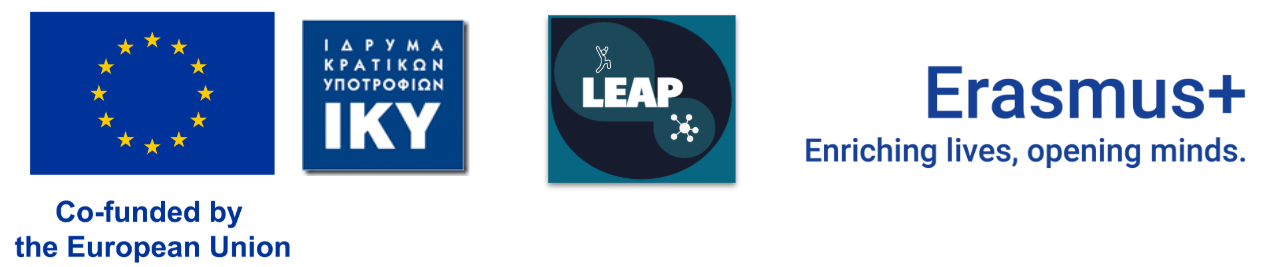

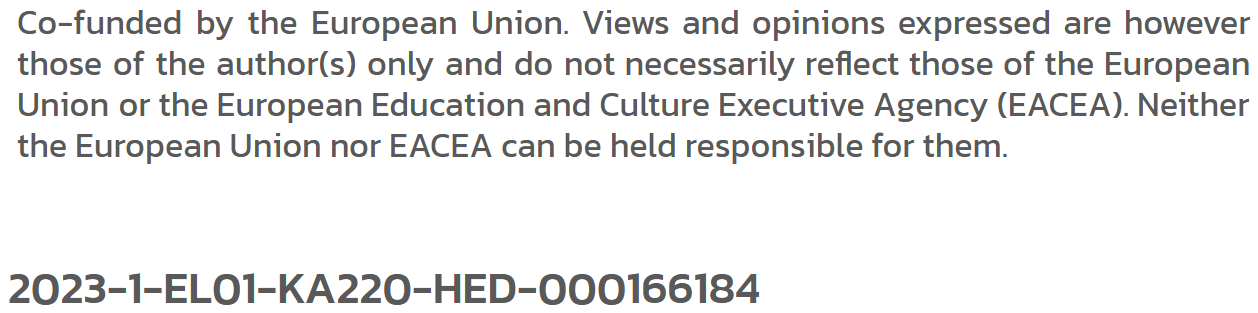

# Final Project, Option 2: Does a neural network beat a classical model?

This project compares logistic regression with a small neural network on the Adult Census Income data set. Each row describes a person using numeric features, such as age and hours worked per week, and categorical features, such as occupation and education. The target is whether that person's annual income exceeds $50,000.

The central question is whether the neural network improves prediction enough to justify its additional complexity. Both models are evaluated on the same held-out test set. F1 for the higher-income class is the main comparison metric, supported by accuracy, precision, recall, and confusion matrices.

The public-agency scenario is an illustration of the possible consequences of model errors. These historical individual records do not establish suitability for present-day household benefit decisions.

The notebook follows the supplied Parts A-D. Run the cells from top to bottom. The local environment was tested with Python 3.11 and the versions pinned in `requirements.txt`; the first data download requires internet access. Figures and a numerical summary are saved under `results/`.

## Part A. Setup and data

We start with the imports. This cell loads everything the notebook needs, so we run it once at the top.

In [1]:
import os
from pathlib import Path

# Keep caches local and use a small, reproducible CPU configuration.
CACHE_DIR = Path('.cache')
CACHE_DIR.mkdir(exist_ok=True)
os.environ['KERAS_BACKEND'] = 'tensorflow'
os.environ['KERAS_HOME'] = str(CACHE_DIR / 'keras')
os.environ['MPLCONFIGDIR'] = str(CACHE_DIR / 'matplotlib')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'

import json
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

import tensorflow as tf
import keras
from keras import layers

SEED = 42
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.experimental.enable_op_determinism()
keras.utils.set_random_seed(SEED)

RESULTS_DIR = Path('results')
FIGURE_DIR = RESULTS_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
CLASS_NAMES = ['<=50K', '>50K']
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

print('Python:', platform.python_version())
print('scikit-learn:', version('scikit-learn'))
print('Keras:', keras.__version__, '| backend:', keras.backend.backend())
print('Random seed:', SEED)

Python: 3.11.15
scikit-learn: 1.7.2
Keras: 3.11.3 | backend: tensorflow
Random seed: 42


### Loading the data

We download the Adult data set from OpenML. The features arrive in `X` as a table, and the target in `y` as text, either `>50K` or `<=50K`. The download runs once and may take a moment.

In [2]:
adult = fetch_openml(
    name='adult', version=2, as_frame=True,
    data_home=CACHE_DIR / 'openml',
)
X, y = adult.data.copy(), adult.target.copy()

print('Rows and columns:', X.shape)
print('OpenML data ID:', adult.details['id'])
print('Target counts:', y.value_counts().to_dict())
display(X.head())

missing = X.isna().sum()
print('Missing values in columns that require imputation:')
display(missing[missing > 0].rename('Missing rows').to_frame())

Rows and columns: (48842, 14)
OpenML data ID: 1590
Target counts: {'<=50K': 37155, '>50K': 11687}


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States


Missing values in columns that require imputation:


,Missing rows
workclass,2799
occupation,2809
native-country,857


### Encoding the target

The target is text with two values. We convert it to numbers so both models can use it. `LabelEncoder` maps the two classes to 0 and 1 in alphabetical order, so `<=50K` becomes 0 and `>50K` becomes 1. The higher income class is therefore the positive class, labelled 1.

In [3]:
target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y)
assert list(target_encoder.classes_) == CLASS_NAMES

print('Target mapping:', dict(zip(target_encoder.classes_, [0, 1])))
print(f'Positive rate (share earning >50K): {y.mean():.3%}')

Target mapping: {'<=50K': 0, '>50K': 1}
Positive rate (share earning >50K): 23.928%


### Train and test split

We split the data into a training set and a test set before doing anything else, and we keep the class balance with `stratify`, exactly as in Module 3. Both models are trained on the training set and judged on the same held-back test set, so the comparison is fair.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y,
)

print('Training rows:', X_train.shape[0])
print('Test rows:    ', X_test.shape[0])
print(f'Positive rate: train={y_train.mean():.3%}, test={y_test.mean():.3%}')
assert set(X_train.index).isdisjoint(X_test.index)

Training rows: 39073
Test rows:     9769
Positive rate: train=23.927%, test=23.933%


### Numeric and categorical columns

The two kinds of feature need different preprocessing, so we sort the columns into a numeric group and a categorical group. We detect them from the column data types.

In [5]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

print("Numeric features:    ", numeric_features)
print("Categorical features:", categorical_features)

Numeric features:     ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


## Part B. The classical model

Numeric and categorical features need different preprocessing. Numeric missing values are replaced by the training median, then the features are standardised. Categorical missing values are replaced by the most frequent training category, then one-hot encoded.

`handle_unknown='ignore'` allows the model to receive a category that was absent during fitting. Its encoded entries for that feature will be zero. All fitted preprocessing is kept inside the model pipeline, including during cross-validation.

In [6]:
numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])

categorical_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocess = ColumnTransformer([
    ('numeric', numeric_pipe, numeric_features),
    ('categorical', categorical_pipe, categorical_features),
])

print('Preprocessing:', len(numeric_features), 'numeric and',
      len(categorical_features), 'categorical features')

Preprocessing: 6 numeric and 8 categorical features


### The full pipeline

Wrap the preprocessor and a classifier into a single pipeline. We use `LogisticRegression`, the classifier from Module 3.

In [7]:
# Use a copy so that preparing the neural network cannot change this model.
clf = Pipeline([
    ('preprocess', clone(preprocess)),
    ('model', LogisticRegression(max_iter=1000, random_state=SEED)),
])
print(clf)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'fnlwgt',
                                                   'education-num',
                                                   'capital-gain',
                                                   'capital-loss',
                                                   'hours-per-week']),
                                                 ('categorical',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(s

### Cross-validation

Before the final test, estimate performance with cross-validation on the training data, as in Module 3. A single split can be lucky or unlucky; averaging over folds gives a steadier estimate.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scores = cross_val_score(
    clf, X_train, y_train, cv=cv, scoring='f1', n_jobs=1,
)

display(pd.DataFrame({'Fold': range(1, 6), 'F1': cv_scores}).round(4))
print(f'Mean CV F1: {cv_scores.mean():.4f}')
print(f'Standard deviation across folds: {cv_scores.std():.4f}')

,Fold,F1
0,1,0.6714
1,2,0.6665
2,3,0.6528
3,4,0.6454
4,5,0.6517


Mean CV F1: 0.6576
Standard deviation across folds: 0.0098


### Fit and evaluate on the test set

Now fit the pipeline on the whole training set and judge it on the test set. Record the accuracy and the F1 score, and draw the confusion matrix. Keep these numbers; you will compare them with the network in Part D.

Logistic regression: F1=0.6562, accuracy=0.8524


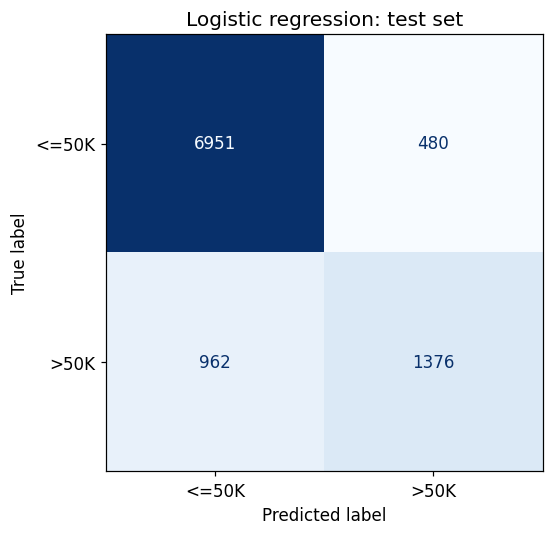

In [9]:
clf.fit(X_train, y_train)
clf_pred = clf.predict(X_test)
clf_acc = accuracy_score(y_test, clf_pred)
clf_f1 = f1_score(y_test, clf_pred)
clf_cm = confusion_matrix(y_test, clf_pred, labels=[0, 1])

print(f'Logistic regression: F1={clf_f1:.4f}, accuracy={clf_acc:.4f}')
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(clf_cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d',
)
ax.set_title('Logistic regression: test set')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'logistic_regression_confusion_matrix.png', dpi=180)
plt.show()

## Part C. The neural network

**Prediction recorded before training the network:** I expect the neural network to achieve a slightly higher F1 score than logistic regression. It can learn nonlinear relationships and interactions between features, such as education, age, and hours worked, while logistic regression uses additive effects on the log odds. I expect a modest difference because logistic regression is already a useful baseline for this structured data, and the network may overfit.

The network needs a numeric array. It uses the same preprocessing steps as logistic regression, fitted independently. Keras reserves the last 10% of the provided training rows for validation before shuffling; to keep that validation portion independent, the network's preprocessor is fitted only on the first 90%. It then transforms both the full training array and the test set. The training rows were already shuffled by `train_test_split`.

This is a small refinement of the starter's preprocessing order. It keeps the prescribed `validation_split=0.1` training procedure while preventing validation rows from influencing the imputation, scaling, or category vocabulary. The test set is never used to fit either model or its preprocessing.

In [10]:
VALIDATION_FRACTION = 0.1
nn_fit_rows = int(len(X_train) * (1 - VALIDATION_FRACTION))
nn_preprocess = clone(preprocess)
nn_preprocess.fit(X_train.iloc[:nn_fit_rows])

X_train_prep = nn_preprocess.transform(X_train).astype('float32')
X_test_prep = nn_preprocess.transform(X_test).astype('float32')

assert np.isfinite(X_train_prep).all() and np.isfinite(X_test_prep).all()
print('Transformed training shape:', X_train_prep.shape)
print('Rows for network fitting:', nn_fit_rows)
print('Rows for validation:', len(X_train) - nn_fit_rows)
print(f'Validation positive rate: {y_train[nn_fit_rows:].mean():.3%}')

Transformed training shape: (39073, 105)
Rows for network fitting: 35165
Rows for validation: 3908
Validation positive rate: 23.772%


### Build the network

Build a small dense network for this feature array, in the Sequential style from Module 5. The task is binary, so the output is a single unit with a sigmoid activation, giving the probability of the positive class.

In [11]:
keras.utils.set_random_seed(SEED)
net = keras.Sequential([
    layers.Input(shape=(X_train_prep.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid'),
], name='adult_income_network')

net.summary()

Model: "adult_income_network"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         6,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,897 (34.75 KB)

 Trainable params: 8,897 (34.75 KB)

 Non-trainable params: 0 (0.00 B)

### Compile and train

Compile and train the network. Because the output is a single sigmoid unit, the loss is `binary_crossentropy`. Use EarlyStopping so training stops once the validation loss stops improving.

In [12]:
net.compile(
    optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'],
)
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True, verbose=1,
)
history = net.fit(
    X_train_prep, y_train,
    validation_split=VALIDATION_FRACTION,
    epochs=20, batch_size=128,
    callbacks=[early_stopping],
    verbose=2,
)

Epoch 1/20


275/275 - 1s - 4ms/step - accuracy: 0.8183 - loss: 0.3742 - val_accuracy: 0.8498 - val_loss: 0.3297


Epoch 2/20


275/275 - 0s - 1ms/step - accuracy: 0.8495 - loss: 0.3210 - val_accuracy: 0.8541 - val_loss: 0.3283


Epoch 3/20


...

275/275 - 0s - 1ms/step - accuracy: 0.8541 - loss: 0.3114 - val_accuracy: 0.8539 - val_loss: 0.3305


Epoch 5/20


275/275 - 0s - 1ms/step - accuracy: 0.8564 - loss: 0.3084 - val_accuracy: 0.8534 - val_loss: 0.3317


Epoch 5: early stopping


Restoring model weights from the end of the best epoch: 2.


### Training and validation loss

Early stopping selects the weights from the epoch with the lowest validation loss. These curves help check whether additional training improves performance on the validation rows. Dropout is active during training and switched off during validation, so a lower validation loss than training loss is not by itself an error.

Epochs completed: 5
Best validation-loss epoch: 2


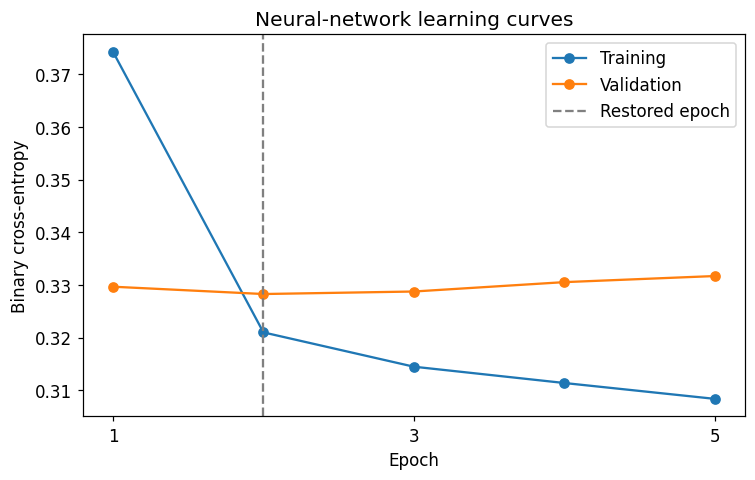

In [13]:
epochs = np.arange(1, len(history.history['loss']) + 1)
best_epoch = int(np.argmin(history.history['val_loss'])) + 1
print('Epochs completed:', len(epochs))
print('Best validation-loss epoch:', best_epoch)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(epochs, history.history['loss'], marker='o', label='Training')
ax.plot(epochs, history.history['val_loss'], marker='o', label='Validation')
ax.axvline(best_epoch, linestyle='--', color='gray', label='Restored epoch')
ax.set(xlabel='Epoch', ylabel='Binary cross-entropy', title='Neural-network learning curves')
ax.set_xticks(epochs[::2])
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'training_curves.png', dpi=180)
plt.show()

### Evaluate on the test set

Judge the network on the same test set. The network outputs probabilities, so a prediction is positive when the probability is above 0.5. Record the accuracy and F1, and draw the confusion matrix.

Neural network: F1=0.6809, accuracy=0.8590


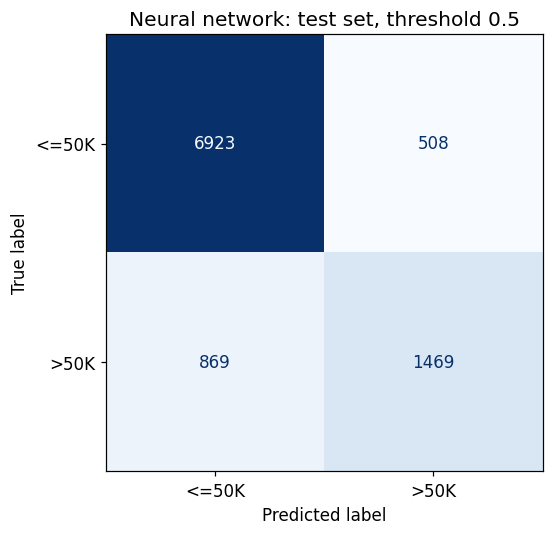

In [14]:
nn_prob = net.predict(X_test_prep, batch_size=128, verbose=0).ravel()
nn_pred = (nn_prob > 0.5).astype(int)
nn_acc = accuracy_score(y_test, nn_pred)
nn_f1 = f1_score(y_test, nn_pred)
nn_cm = confusion_matrix(y_test, nn_pred, labels=[0, 1])

print(f'Neural network: F1={nn_f1:.4f}, accuracy={nn_acc:.4f}')
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(nn_cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d',
)
ax.set_title('Neural network: test set, threshold 0.5')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'neural_network_confusion_matrix.png', dpi=180)
plt.show()

## Part D. The comparison

Now answer the central question. You have four numbers: the accuracy and F1 of the classical model, and the accuracy and F1 of the network, all measured on the same test set. Because the higher-income class is the minority class, use F1 as your main comparison metric and accuracy as supporting information.

,F1,Accuracy,Precision,Recall,False positives,False negatives
Model,,,,,,
Logistic regression,0.6562,0.8524,0.7414,0.5885,480,962
Neural network,0.6809,0.8590,0.7430,0.6283,508,869


F1 difference (network - logistic regression): +0.0247
Accuracy difference: +0.67 percentage points
Always predicting <=50K: accuracy=0.7607, F1=0.0000


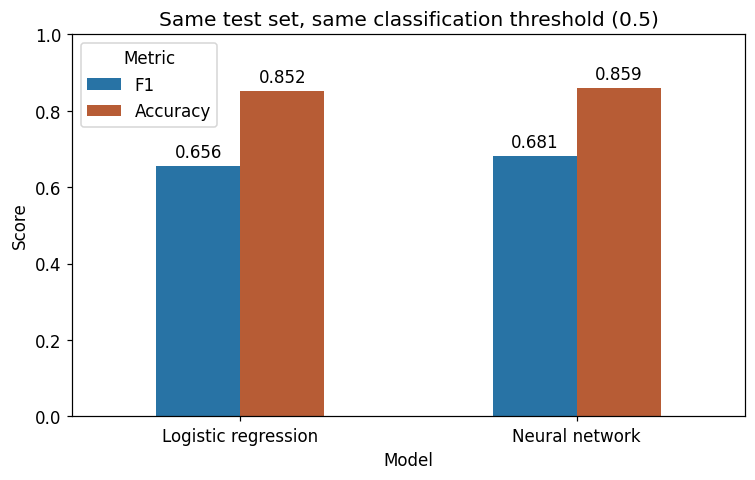

In [15]:
comparison = pd.DataFrame({
    'Model': ['Logistic regression', 'Neural network'],
    'F1': [clf_f1, nn_f1],
    'Accuracy': [clf_acc, nn_acc],
    'Precision': [precision_score(y_test, clf_pred), precision_score(y_test, nn_pred)],
    'Recall': [recall_score(y_test, clf_pred), recall_score(y_test, nn_pred)],
    'False positives': [int(clf_cm[0, 1]), int(nn_cm[0, 1])],
    'False negatives': [int(clf_cm[1, 0]), int(nn_cm[1, 0])],
}).set_index('Model')
display(comparison.round(4))

print(f'F1 difference (network - logistic regression): {nn_f1 - clf_f1:+.4f}')
print(f'Accuracy difference: {100 * (nn_acc - clf_acc):+.2f} percentage points')
print(f'Always predicting <=50K: accuracy={np.mean(y_test == 0):.4f}, F1=0.0000')

ax = comparison[['F1', 'Accuracy']].plot.bar(
    figsize=(7, 4.5), rot=0, color=['#2873a5', '#b75c35'],
)
ax.set(ylabel='Score', ylim=(0, 1), title='Same test set, same classification threshold (0.5)')
ax.legend(title='Metric', loc='upper left')
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.3f', padding=3)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'model_comparison.png', dpi=180)
plt.show()

### Ethical considerations

The data include sex, race, and native country, so both models may reproduce historical inequalities; the overall F1 score does not show whether error rates are similar across these groups. If a predicted high income were used to exclude someone from a means-tested benefit, a false positive could wrongly exclude a lower-income person, while a false negative could include a higher-income person; the consequences depend on how the agency uses the prediction. Logistic regression is easier to inspect, but neither model is automatically fair, and any real use would require appropriate current data, checks of errors across groups, and a way to review decisions.

## Wrapping up

The neural network reached a test F1 of 0.6809, compared with 0.6562 for logistic regression, a gain of 0.0247. My prediction of a small improvement was correct; accuracy also rose from 0.8524 to 0.8590. Accuracy alone hides the class imbalance: always predicting `<=50K` would score 0.7607 accuracy but F1 of zero for `>50K`. The network identified 1,469 of the 2,338 higher-income test cases, compared with 1,376 for logistic regression, reducing false negatives from 962 to 869 while increasing false positives from 480 to 508. It found more of the positive class at the cost of more false alarms. Its extra complexity gave a modest gain here, but whether that is worthwhile depends on the costs of each error and the need to explain decisions. A possible reason for the improvement is that the network can represent nonlinear feature relationships; this run cannot establish which relationships mattered. The result comes from one data split and one network seed, so it does not show that the network is always better.

### Reflection

Keeping preprocessing inside the training procedure worked well: the pipeline refits it within each cross-validation fold, and both models are evaluated on the same test rows. The main difficulty was keeping the network's validation rows separate when fitting the preprocessor, because Keras takes the last 10% of the training array for validation. Fitting preprocessing on the first 90% keeps that check independent. The confusion matrices also made the result easier to interpret: the network's higher F1 came with fewer false negatives but more false positives.

With more time, I would repeat the network across random seeds, compare errors across sex, race, and native-country groups, and examine how the decision threshold changes the two kinds of error. Any threshold would be chosen using validation data before evaluating a new held-out test set. The main lesson is that a small score improvement is only part of the decision; repeatability, error costs, and the ability to explain predictions also matter.

### Reproducibility and saved results

The following cell saves the numerical results, training history, and software versions. The seed and deterministic TensorFlow operations improve reproducibility, although other software versions or hardware may give slightly different results. This comparison uses one train/test split and one neural-network seed; it does not establish superiority across all possible runs.

In [16]:
assert clf_cm.sum() == nn_cm.sum() == len(y_test)
assert len(clf_pred) == len(nn_pred) == len(y_test)
assert np.isfinite(nn_prob).all() and np.all((nn_prob >= 0) & (nn_prob <= 1))

metrics = {
    'dataset': {'name': 'adult', 'version': 2, 'openml_id': adult.details['id'],
                'rows': len(X), 'features': X.shape[1],
                'class_counts': {name: int(np.sum(y == i)) for i, name in enumerate(CLASS_NAMES)},
                'missing_by_column': missing[missing > 0].astype(int).to_dict()},
    'seed': SEED,
    'train_rows': len(X_train), 'test_rows': len(X_test),
    'test_class_counts': np.bincount(y_test).tolist(),
    'cv_f1_scores': cv_scores.tolist(),
    'cv_f1_mean': float(cv_scores.mean()), 'cv_f1_std': float(cv_scores.std()),
    'models': {
        name: {k: (int(v) if k in ['False positives', 'False negatives'] else float(v))
               for k, v in row.items()}
        for name, row in comparison.to_dict(orient='index').items()
    },
    'logistic_confusion_matrix': clf_cm.tolist(),
    'neural_confusion_matrix': nn_cm.tolist(),
    'network_fit_rows': nn_fit_rows,
    'network_validation_rows': len(X_train) - nn_fit_rows,
    'network_input_features': X_train_prep.shape[1],
    'logistic_input_features': clf.named_steps['model'].coef_.shape[1],
    'network_parameters': net.count_params(),
    'logistic_parameters': int(clf.named_steps['model'].coef_.size + clf.named_steps['model'].intercept_.size),
    'network_epochs': len(epochs), 'best_epoch': best_epoch,
    'history': {k: [float(v) for v in values] for k, values in history.history.items()},
    'python': platform.python_version(),
    'packages': {p: version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'keras', 'tensorflow-cpu']},
}
(RESULTS_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2) + '\n')
comparison.to_csv(RESULTS_DIR / 'model_comparison.csv')
print('Saved results/metrics.json, results/model_comparison.csv, and four figures.')

Saved results/metrics.json, results/model_comparison.csv, and four figures.


### Sources

- Supplied course materials: `ML_Final_Project_Brief.pdf` and `ML_Final_Project_Portfolio_Instructions.pdf`.
- [Adult data set, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/2/adult) and [OpenML Adult version 2, ID 1590](https://www.openml.org/d/1590).
- [scikit-learn: preventing data leakage with pipelines](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
- [Keras model training API](https://keras.io/api/models/model_training_apis/) for the validation split and training procedure; [EarlyStopping](https://keras.io/api/callbacks/early_stopping/) for restoring the best weights.
